In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from sklearn.model_selection import train_test_split

from sklearn.preprocessing import PolynomialFeatures, StandardScaler

from sklearn.linear_model import LinearRegression, SGDRegressor

from sklearn.metrics import r2_score

from sklearn.pipeline import Pipeline

In [3]:
X = 6 * np.random.rand(200,1) - 3
y = 0.8*X**(2) + 0.9*X + 2 + np.random.randn(200,1)

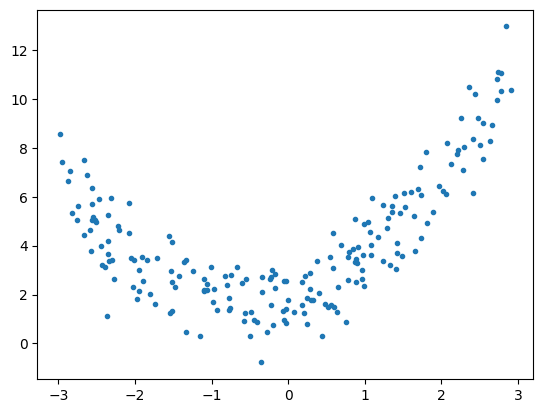

In [4]:
plt.plot(X,y ,'.')

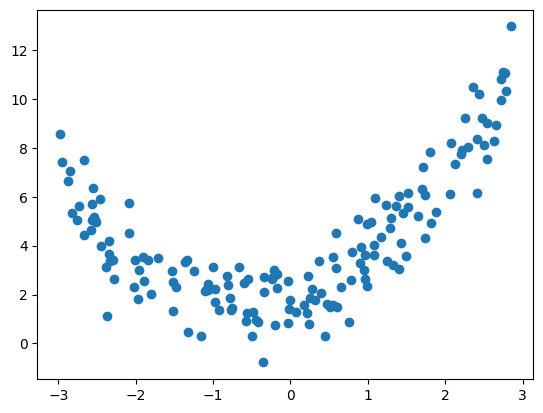

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.2, random_state = 2)
plt.plot(X_train,y_train,'o')

In [6]:
lr = LinearRegression()
lr.fit(X_train,y_train)

LinearRegression()

In [7]:
y_pred = lr.predict(X_test)
y_pred

array([[5.34399237],
       [4.00950763],
       [4.39625876],
       [5.77916864],
       [6.2072009 ],
       [2.7770347 ],
       [2.51997413],
       [4.78003529],
       [5.30183894],
       [4.32357332],
       [4.79778589],
       [2.59906675],
       [3.44178253],
       [4.80862009],
       [4.93344838],
       [2.56795855],
       [4.64200965],
       [2.41996641],
       [2.99472943],
       [4.14660822],
       [3.68244968],
       [5.18281795],
       [4.15863094],
       [3.15336377],
       [5.56331729],
       [2.67100719],
       [4.40139821],
       [2.85009543],
       [5.59097796],
       [3.20859323],
       [3.1332275 ],
       [2.65812057],
       [5.1367696 ],
       [4.67132039],
       [4.73501153],
       [4.15659611],
       [4.0467554 ],
       [3.11910863],
       [2.37918931],
       [4.80627045]])

In [8]:
r2_score(y_test,y_pred)

-0.015839069405392925

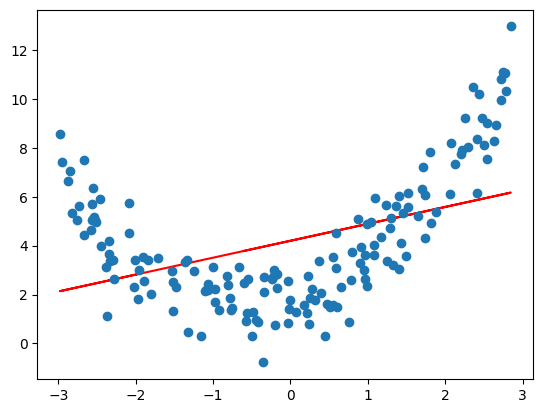

In [9]:
plt.plot(X_train,lr.predict(X_train),color='red')
plt.plot(X_train,y_train,'o')

In [10]:
pf = PolynomialFeatures(degree=2, include_bias=True)
X_train_poly = pf.fit_transform(X_train)
X_test_poly = pf.transform(X_test)

X_train_poly

array([[ 1.00000000e+00, -6.02659444e-01,  3.63198406e-01],
       [ 1.00000000e+00,  2.65727064e+00,  7.06108726e+00],
       [ 1.00000000e+00, -1.89694647e+00,  3.59840592e+00],
       [ 1.00000000e+00,  2.72393826e+00,  7.41983962e+00],
       [ 1.00000000e+00, -2.66097127e+00,  7.08076808e+00],
       [ 1.00000000e+00, -5.66133623e-01,  3.20507279e-01],
       [ 1.00000000e+00,  2.24755075e-01,  5.05148439e-02],
       [ 1.00000000e+00,  4.00338917e-01,  1.60271248e-01],
       [ 1.00000000e+00, -1.35756018e+00,  1.84296964e+00],
       [ 1.00000000e+00,  5.86140245e-01,  3.43560387e-01],
       [ 1.00000000e+00,  1.40600921e+00,  1.97686189e+00],
       [ 1.00000000e+00, -1.09324146e+00,  1.19517688e+00],
       [ 1.00000000e+00,  5.87419531e-01,  3.45061705e-01],
       [ 1.00000000e+00, -2.33590396e+00,  5.45644732e+00],
       [ 1.00000000e+00,  2.78136893e+00,  7.73601312e+00],
       [ 1.00000000e+00,  5.51743711e-01,  3.04421123e-01],
       [ 1.00000000e+00,  4.77550253e-01

In [11]:
lr2 = LinearRegression()
lr2.fit(X_train_poly, y_train)

LinearRegression()

In [12]:
y_pred_2 = lr2.predict(X_test_poly)
r2_score(y_test, y_pred_2)

0.7356744436533099

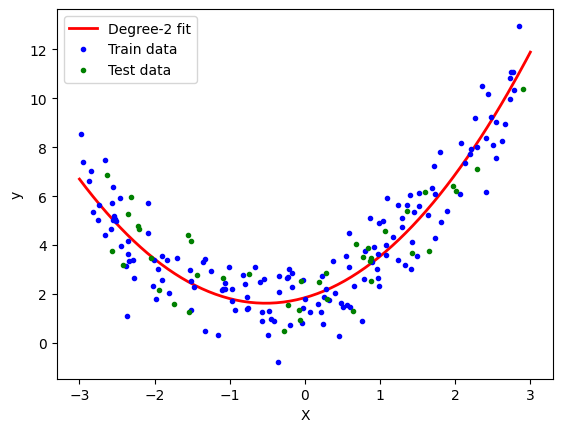

In [13]:
X_new = np.linspace(-3, 3, 200).reshape(-1, 1)   # evenly spaced, sorted inputs
X_new_poly = pf.transform(X_new)               # same feature expansion as training
y_new = lr2.predict(X_new_poly)

plt.plot(X_new, y_new, 'r-', linewidth=2, label='Degree-2 fit')
plt.plot(X_train, y_train, 'b.', label='Train data')
plt.plot(X_test, y_test, 'g.', label='Test data')
plt.xlabel('X'); plt.ylabel('y'); plt.legend()
plt.show()